# Course 16: Algorithms Behind Modern AI
## Session 1: Counting cost: arrays, memory and Big-O for models

**Goal:** count the multiply–adds of matrix products and of self-attention and compare the counts with measured time, read an array's strides to tell views from copies, count the copies behind amortized appends, and build CSR sparse storage to see when sparse beats dense.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: count the multiply–adds of a small product
One **multiply–add** is one multiplication whose result is added to a running sum, $s \leftarrow s + a \cdot b$. It is the unit in which we count the cost of matrix code.

Take $A$ of shape 2 × 3 and $B$ of shape 3 × 2. Each entry of $C = AB$ is the dot product of one row of $A$ with one column of $B$: 3 multiply–adds. $C$ has 2 × 2 = 4 entries, so the product costs 2 × 3 × 2 = 12 multiply–adds. In general an $m \times n$ matrix times an $n \times p$ matrix costs $m \cdot n \cdot p$.

On paper, compute $AB$ for the two matrices below and count your multiplications. Then count the cost of $BA$ (a 3 × 2 times a 2 × 3 matrix). Is it the same? Then run the cell.

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[_v] = "1"              # one thread for NumPy, so timings are comparable; set before NumPy is imported
import sys, time
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

t_start = time.time()

def matmul_count(A, B):
    # C = A B for lists of lists, with a counter of multiply-adds
    m, n, p = len(A), len(B), len(B[0])
    assert len(A[0]) == n, "inner sizes must agree"
    C = [[0] * p for _ in range(m)]
    count = 0
    for i in range(m):                  # every row of A
        for j in range(p):              # every column of B
            s = 0
            for k in range(n):          # one dot product of n terms
                s += A[i][k] * B[k][j]
                count += 1
            C[i][j] = s
    return C, count

A = [[1, 2, 3],
     [4, 5, 6]]                         # 2 x 3
B = [[1, 0],
     [2, 1],
     [0, 3]]                            # 3 x 2
C, c_ab = matmul_count(A, B)
D, c_ba = matmul_count(B, A)
print("A B =", C, "| multiply-adds:", c_ab, "= 2 * 3 * 2")
print("B A =", D, "| multiply-adds:", c_ba, "= 3 * 2 * 3")

A B = [[5, 11], [14, 23]] | multiply-adds: 12 = 2 * 3 * 2
B A = [[1, 2, 3], [6, 9, 12], [12, 15, 18]] | multiply-adds: 18 = 3 * 2 * 3


### 2. A counter in the triple loop, and the constant that Big-O hides
The loop above works for any shapes, so we can check the formula $m \cdot n \cdot p$ by counting. The third shape below is a **dense layer on a batch**: 32 inputs of width 784 times a 784 × 128 weight matrix.

Then we time the same 120 × 120 product twice: with the Python loops, and with NumPy's `A @ B`, which calls compiled code. Both do the same 1,728,000 multiply–adds, so both are $O(n^3)$. Big-O says how the cost **grows**; it says nothing about the constant in front.

In [2]:
rng = np.random.default_rng(0)
print(" m    n    p  | multiply-adds counted |     m * n * p")
for m, n, p in [(2, 3, 2), (5, 7, 3), (32, 784, 128), (120, 120, 120)]:
    A, B = rng.normal(size=(m, n)), rng.normal(size=(n, p))
    t0 = time.perf_counter()
    C, count = matmul_count(A.tolist(), B.tolist())
    t_loop = time.perf_counter() - t0
    assert np.allclose(C, A @ B)                               # the loop computes the same product as NumPy
    print(f"{m:3d} {n:4d} {p:4d}  | {count:21,d} | {m * n * p:13,d}")

ts = []
for _ in range(20):                                            # NumPy on the last (120 x 120) pair: best of 20 runs
    t0 = time.perf_counter(); A @ B; ts.append(time.perf_counter() - t0)
t_numpy = min(ts)
print(f"time for the 120 x 120 x 120 product, Python loops: {t_loop * 1e3:.1f} ms")
print(f"time for the 120 x 120 x 120 product, NumPy:        {t_numpy * 1e3:.3f} ms")
print(f"time ratio, loops / NumPy: about {t_loop / t_numpy:,.0f}")

 m    n    p  | multiply-adds counted |     m * n * p
  2    3    2  |                    12 |            12
  5    7    3  |                   105 |           105


 32  784  128  |             3,211,264 |     3,211,264
120  120  120  |             1,728,000 |     1,728,000
time for the 120 x 120 x 120 product, Python loops: 92.4 ms
time for the 120 x 120 x 120 product, NumPy:        0.063 ms
time ratio, loops / NumPy: about 1,456


### 3. Self-attention: the cost that grows with $n^2$
One self-attention head on $n$ tokens of width $d$ (Course 4 session 1 explains what each part is for):

* three projections $Q = XW_q$, $K = XW_k$, $V = XW_v$: each is an $(n \times d)(d \times d)$ product, $n d^2$ multiply–adds;
* the scores $S = QK^\top$: $n^2$ entries, each a dot product of $d$ terms, so $n^2 d$;
* a softmax over each row (exponentials and divisions; by convention they are not counted as multiply–adds);
* the weighted sums $PV$: an $(n \times n)(n \times d)$ product, again $n^2 d$;
* the output projection: $n d^2$.

Total: $2n^2 d + 4 n d^2$. The function `mm` below multiplies two matrices and adds $m \cdot n \cdot p$ to a counter, read from the shapes of the arrays that are really multiplied. We keep $d = 64$, double $n$ from 64 to 4,096, and also time each call. On log–log axes a cost $c \cdot n^k$ is a straight line of slope $k$, so we fit a line to the measured times.

    n | score entries n^2 | counted multiply-adds | 2 n^2 d + 4 n d^2 | share of the n^2 part
   64 |             4,096 |             1,572,864 |         1,572,864 |    33.3%
  128 |            16,384 |             4,194,304 |         4,194,304 |    50.0%
  256 |            65,536 |            12,582,912 |        12,582,912 |    66.7%
  512 |           262,144 |            41,943,040 |        41,943,040 |    80.0%
 1024 |         1,048,576 |           150,994,944 |       150,994,944 |    88.9%


 2048 |         4,194,304 |           570,425,344 |       570,425,344 |    94.1%


 4096 |        16,777,216 |         2,214,592,512 |     2,214,592,512 |    97.0%


n from 2048 to 4096: score entries x 4.0, all multiply-adds x 3.88
n from   64 to  128: score entries x 4.0, all multiply-adds x 2.67
time for n =   64:     0.08 ms
time for n =  128:     0.20 ms
time for n =  256:     0.65 ms
time for n =  512:     3.98 ms
time for n = 1024:    15.43 ms
time for n = 2048:    57.48 ms
time for n = 4096:   253.62 ms
log-log slope of the exact count for n >= 512: 1.91
log-log slope of the measured time for n >= 512: 1.99


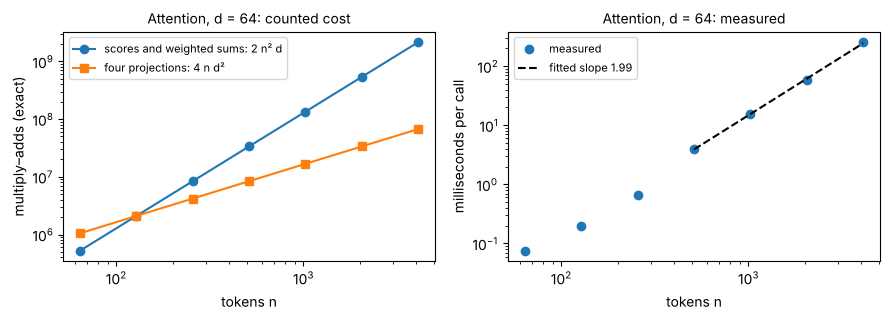

In [3]:
MACS = {"count": 0}

def mm(A, B):
    # matrix product that also counts multiply-adds from the shapes: (m x n)(n x p) costs m * n * p
    MACS["count"] += A.shape[0] * A.shape[1] * B.shape[1]
    return A @ B

def attention(X, Wq, Wk, Wv, Wo):
    Q, K, V = mm(X, Wq), mm(X, Wk), mm(X, Wv)              # three projections: 3 n d^2
    S = mm(Q, K.T) / np.sqrt(X.shape[1])                    # the n x n scores: n^2 d
    S -= S.max(axis=1, keepdims=True)
    P = np.exp(S); P /= P.sum(axis=1, keepdims=True)        # softmax over each row
    return mm(mm(P, V), Wo)                                 # weighted sums: n^2 d; output projection: n d^2

d = 64
Ws = [(rng.normal(size=(d, d)) / np.sqrt(d)).astype(np.float32) for _ in range(4)]
ns, counts, times = [64, 128, 256, 512, 1024, 2048, 4096], [], []
print("    n | score entries n^2 | counted multiply-adds | 2 n^2 d + 4 n d^2 | share of the n^2 part")
for n in ns:
    X = rng.normal(size=(n, d)).astype(np.float32)
    MACS["count"] = 0
    attention(X, *Ws)
    counts.append(MACS["count"])
    assert counts[-1] == 2 * n * n * d + 4 * n * d * d
    print(f"{n:5d} | {n * n:17,d} | {counts[-1]:21,d} | {2 * n * n * d + 4 * n * d * d:17,d} | {2 * n * n * d / counts[-1]:8.1%}")
    ts = []
    for _ in range(5):
        t0 = time.perf_counter(); attention(X, *Ws); ts.append(time.perf_counter() - t0)
    times.append(min(ts))
print(f"n from 2048 to 4096: score entries x {ns[-1] ** 2 / ns[-2] ** 2:.1f}, all multiply-adds x {counts[-1] / counts[-2]:.2f}")
print(f"n from   64 to  128: score entries x {ns[1] ** 2 / ns[0] ** 2:.1f}, all multiply-adds x {counts[1] / counts[0]:.2f}")

for n, t in zip(ns, times):
    print(f"time for n = {n:4d}: {t * 1e3:8.2f} ms")
big = slice(3, None)                                        # fit where the n^2 part dominates: n >= 512
lognn, logt = np.log(np.array(ns[big], dtype=float)), np.log(np.array(times[big]))
slope_time, icpt = np.polyfit(lognn, logt, 1)
slope_count = np.polyfit(lognn, np.log(np.array(counts[big], dtype=float)), 1)[0]
print(f"log-log slope of the exact count for n >= 512: {slope_count:.2f}")
print(f"log-log slope of the measured time for n >= 512: {slope_time:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
nn = np.array(ns, dtype=float)
ax[0].loglog(nn, 2 * nn**2 * d, "o-", label="scores and weighted sums: 2 n² d")
ax[0].loglog(nn, 4 * nn * d * d, "s-", label="four projections: 4 n d²")
ax[0].set_xlabel("tokens n"); ax[0].set_ylabel("multiply–adds (exact)"); ax[0].set_title("Attention, d = 64: counted cost", fontsize=10)
ax[0].legend(fontsize=8)
ax[1].loglog(nn, np.array(times) * 1e3, "o", label="measured")
ax[1].loglog(nn[big], np.exp(icpt) * nn[big] ** slope_time * 1e3, "k--", label=f"fitted slope {slope_time:.2f}")
ax[1].set_xlabel("tokens n"); ax[1].set_ylabel("milliseconds per call"); ax[1].set_title("Attention, d = 64: measured", fontsize=10)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4. How an array lives in memory: one buffer, a shape and strides
A NumPy array is one **contiguous buffer** of bytes plus a little bookkeeping: the `shape`, the `dtype` (how many bytes per element) and the **strides**: how many bytes to jump to move one step along each axis. Element $(i, j)$ lives at byte `i * strides[0] + j * strides[1]` from the start.

So a transpose only swaps the two strides, and a slice only changes the start and the strides. No data moves: the result is a **view** of the same buffer. `np.shares_memory` tells you whether two arrays share bytes. A view costs $O(1)$; a copy costs $O(\text{size})$.

Before running: `a` below has 3 rows and 4 columns of 8-byte integers. What are its strides? What are the strides of `a.T`?

In [4]:
a = np.arange(12, dtype=np.int64).reshape(3, 4)
print(a)
print("itemsize:", a.itemsize, "bytes | buffer:", a.nbytes, "bytes")
cases = [("a", a), ("a.T (transpose)", a.T), ("a[:, ::2] (every second column)", a[:, ::2]), ("a[1:, :] (drop row 0)", a[1:, :]),
         ("a.reshape(4, 3)", a.reshape(4, 3)), ("a.reshape(12)", a.reshape(12)), ("a.T.reshape(12)", a.T.reshape(12)),
         ("a[[0, 2]] (rows picked by a list)", a[[0, 2]]), ("a.T.copy()", a.T.copy())]
print(f"\n{'expression':34s} | shape   | strides  | shares memory with a | C-contiguous")
for name, v in cases:
    print(f"{name:34s} | {str(v.shape):7s} | {str(v.strides):8s} | {str(np.shares_memory(a, v)):20s} | {v.flags['C_CONTIGUOUS']}")

t = a.T
t[0, 1] = 99                                   # writing through a view changes the original
print("\nafter t = a.T; t[0, 1] = 99:  a[1, 0] =", a[1, 0])
a[1, 0] = 4
print("a.T read in order:", a.T.reshape(12), "(a new buffer: the transposed order is not the buffer's order)")

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
itemsize: 8 bytes | buffer: 96 bytes

expression                         | shape   | strides  | shares memory with a | C-contiguous
a                                  | (3, 4)  | (32, 8)  | True                 | True
a.T (transpose)                    | (4, 3)  | (8, 32)  | True                 | False
a[:, ::2] (every second column)    | (3, 2)  | (32, 16) | True                 | False
a[1:, :] (drop row 0)              | (2, 4)  | (32, 8)  | True                 | True
a.reshape(4, 3)                    | (4, 3)  | (24, 8)  | True                 | True
a.reshape(12)                      | (12,)   | (8,)     | True                 | True
a.T.reshape(12)                    | (12,)   | (8,)     | False                | True
a[[0, 2]] (rows picked by a list)  | (2, 4)  | (32, 8)  | False                | True
a.T.copy()                         | (4, 3)  | (24, 8)  | False                | True

after t = a.T; t[0, 1] = 99:  a[1, 0] = 99
a.

### 5. Same additions, different order: along the buffer or across it
A processor reads memory in **cache lines**, typically of 64 bytes (16 float32 numbers). Reading a buffer in order uses every number of every line it loads; jumping by a large stride loads a whole line to use one number.

We sum all entries of an $n \times n$ float32 array of ones in two ways: row by row (`x[i, :]`, a contiguous slice in the default row-major or "C" order) and column by column (`x[:, j]`, strides of $4n$ bytes). Both do exactly $n^2$ additions. For the largest size we also store the same numbers column-major ("Fortran" order), where the columns are the contiguous ones.

These are timings, so they change from run to run and from machine to machine.

In [5]:
def sum_by_rows(x):
    s = 0.0
    for i in range(x.shape[0]):
        s += float(x[i, :].sum())
    return s

def sum_by_cols(x):
    s = 0.0
    for j in range(x.shape[1]):
        s += float(x[:, j].sum())
    return s

def best_of(fn, reps=3):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return min(ts)

for n in [2000, 4000, 8000]:
    x = np.ones((n, n), dtype=np.float32)
    assert sum_by_rows(x) == sum_by_cols(x) == n * n
    print(f"n = {n}: {n * n:,d} additions either way, array of {x.nbytes / 1e6:.0f} MB, strides {x.strides}")
    t_r, t_c = best_of(lambda: sum_by_rows(x)), best_of(lambda: sum_by_cols(x))
    print(f"   time, row-major array:    by rows {t_r * 1e3:7.1f} ms, by columns {t_c * 1e3:7.1f} ms (columns / rows = {t_c / t_r:.1f})")
xf = np.asfortranarray(x)                                  # the same numbers, stored column by column
print(f"column-major copy of the last array: strides {xf.strides}, C-contiguous {xf.flags['C_CONTIGUOUS']}")
t_r, t_c = best_of(lambda: sum_by_rows(xf)), best_of(lambda: sum_by_cols(xf))
print(f"   time, column-major array: by rows {t_r * 1e3:7.1f} ms, by columns {t_c * 1e3:7.1f} ms (rows / columns = {t_r / t_c:.1f})")
del x, xf

n = 2000: 4,000,000 additions either way, array of 16 MB, strides (8000, 4)
   time, row-major array:    by rows     2.7 ms, by columns     5.5 ms (columns / rows = 2.1)
n = 4000: 16,000,000 additions either way, array of 64 MB, strides (16000, 4)


   time, row-major array:    by rows    12.2 ms, by columns    24.5 ms (columns / rows = 2.0)


n = 8000: 64,000,000 additions either way, array of 256 MB, strides (32000, 4)


   time, row-major array:    by rows    44.2 ms, by columns   191.2 ms (columns / rows = 4.3)


column-major copy of the last array: strides (4, 32000), C-contiguous False


   time, column-major array: by rows   195.7 ms, by columns    44.1 ms (rows / columns = 4.4)


### 6. Dynamic arrays: why `list.append` is amortized O(1) and `np.append` in a loop is O(n²)
A Python `list` is a **dynamic array** of pointers with some spare capacity. An append writes into a spare slot. When no slot is left, the list asks for a larger block and the old pointers may have to be copied into it.

* If the capacity grows by a **constant factor** (doubling, or CPython's "about one eighth more"), the copies form a geometric series: $n$ appends copy $O(n)$ elements in total. One append is sometimes expensive, but the **average over the sequence** is $O(1)$. This is an **amortized** bound.
* If the capacity grows by **one**, every append copies everything: $0 + 1 + \dots + (n-1) = n(n-1)/2$ copies. This is what `np.append` does: it always returns a new array.

`sys.getsizeof(list)` shows the capacity jumps of a real list. The simulation counts the element copies for three growth rules, assuming that every resize moves the data (a real allocator can sometimes extend a block in place, so this is an upper bound). The rule for CPython is written from its source file `Objects/listobject.c`, and the cell checks it against the measured sizes.

an empty list takes 56 bytes; Python 3.13
length at which the list grew -> new capacity: 1->4, 5->8, 9->16, 17->24, 25->32, 33->40, 41->52, 53->64, 65->76, 77->92, 93->108
the simulated CPython rule gives the same capacities as the real list: True

 appends n |  doubling: copies        2n |  CPython rule: copies        9n |  grow by one: copies       n(n-1)/2
     1,000 |             1,023     2,000 |                 7,556     9,000 |              499,500        499,500
    10,000 |            16,383    20,000 |                83,136    90,000 |           49,995,000     49,995,000
   100,000 |           131,071   200,000 |               798,128   900,000 |        4,999,950,000  4,999,950,000
100,000 appends: doubling resizes 18 x and ends with capacity 131,072; the CPython rule resizes 66 x and ends with 100,116
time for n = 10,000: np.append in a loop     38.6 ms, list.append then np.array   0.77 ms
time for n = 20,000: np.append in a loop     78.4 ms, list.append then np.array   1.46

time for n = 40,000: np.append in a loop    246.2 ms, list.append then np.array   2.89 ms


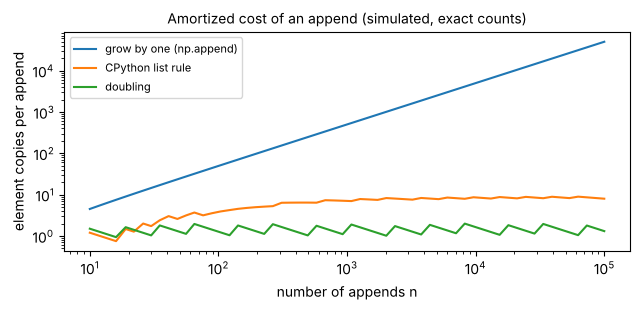

In [6]:
empty = sys.getsizeof([])
lst, last, jumps = [], empty, []
for i in range(1, 101):
    lst.append(None)
    size = sys.getsizeof(lst)
    if size != last:
        jumps.append((i, (size - empty) // 8)); last = size       # 8 bytes per pointer
print(f"an empty list takes {empty} bytes; Python {sys.version_info.major}.{sys.version_info.minor}")
print("length at which the list grew -> new capacity:", ", ".join(f"{i}->{c}" for i, c in jumps))

def grow_double(cap):  return max(1, 2 * cap)
def grow_cpython(cap): return (cap + 1 + ((cap + 1) >> 3) + 6) & ~3      # list_resize() in CPython 3.9 and later
def grow_by_one(cap):  return cap + 1

def simulate(n, grow):
    # n appends; returns (element copies, number of resizes, final capacity, capacity after every resize)
    cap = size = copies = 0
    caps = []
    for _ in range(n):
        if size == cap:
            cap = grow(cap); caps.append(cap)
            copies += size                      # move the old elements into the new block
        size += 1
    return copies, len(caps), cap, caps

print("the simulated CPython rule gives the same capacities as the real list:", simulate(100, grow_cpython)[3] == [c for _, c in jumps])

print(f"\n{'appends n':>10s} | {'doubling: copies':>17s} {'2n':>9s} | {'CPython rule: copies':>21s} {'9n':>9s} | {'grow by one: copies':>20s} {'n(n-1)/2':>14s}")
for n in [1_000, 10_000, 100_000]:
    c2, cp, c1 = simulate(n, grow_double)[0], simulate(n, grow_cpython)[0], simulate(n, grow_by_one)[0]
    print(f"{n:10,d} | {c2:17,d} {2 * n:9,d} | {cp:21,d} {9 * n:9,d} | {c1:20,d} {n * (n - 1) // 2:14,d}")
r2, rp = simulate(100_000, grow_double), simulate(100_000, grow_cpython)
print(f"100,000 appends: doubling resizes {r2[1]} x and ends with capacity {r2[2]:,d}; the CPython rule resizes {rp[1]} x and ends with {rp[2]:,d}")

for n in [10_000, 20_000, 40_000]:
    t0 = time.perf_counter()
    arr = np.empty(0)
    for i in range(n):
        arr = np.append(arr, i)                 # a new array every time
    t_np = time.perf_counter() - t0
    t0 = time.perf_counter()
    out = []
    for i in range(n):
        out.append(i)
    arr2 = np.array(out, dtype=float)           # append to a list, convert once at the end
    t_list = time.perf_counter() - t0
    assert np.array_equal(arr, arr2)
    print(f"time for n = {n:6,d}: np.append in a loop {t_np * 1e3:8.1f} ms, list.append then np.array {t_list * 1e3:6.2f} ms")

grid = np.unique(np.round(np.geomspace(10, 100_000, 60)).astype(int))
plt.figure(figsize=(6.5, 3.2))
for grow, label in [(grow_by_one, "grow by one (np.append)"), (grow_cpython, "CPython list rule"), (grow_double, "doubling")]:
    plt.loglog(grid, [simulate(int(n), grow)[0] / n for n in grid], label=label)
plt.xlabel("number of appends n"); plt.ylabel("element copies per append")
plt.title("Amortized cost of an append (simulated, exact counts)", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7. Sparse matrices: COO and CSR from scratch
Most entries of a bag-of-words matrix, a graph's adjacency matrix or a one-hot vector are zero. A sparse format stores only the non-zeros.

* **COO** (coordinate format): three arrays of the same length, `row`, `col` and `value`, one entry per non-zero, in any order. Easy to build.
* **CSR** (compressed sparse row): `data` (the non-zero values, row after row), `indices` (the column of each value) and `indptr` (where each row starts in the other two; length rows + 1). Row $i$ is `data[indptr[i]:indptr[i+1]]`.

By hand first: for the 3 × 4 matrix below, write the three CSR arrays on paper. Then we build CSR from COO with a **counting sort** (count the non-zeros of each row, take running sums, then place every entry): $O(\text{nnz} + \text{rows})$, where nnz is the number of non-zeros. A sparse matrix–vector product (SpMV) then needs exactly nnz multiply–adds, not rows × columns.

The large matrix imitates a bag-of-words matrix: 2,000 documents × 5,000 words with 1% of the entries non-zero. Its numbers are random (synthetic).

In [7]:
def coo_to_csr(m, rows, cols, vals):
    # COO -> CSR by counting sort; the entries keep their order inside each row
    indptr = [0] * (m + 1)
    for r in rows:                              # 1. count the non-zeros of every row
        indptr[r + 1] += 1
    for i in range(m):                          # 2. running sums: where each row starts
        indptr[i + 1] += indptr[i]
    indices, data = [0] * len(vals), [0.0] * len(vals)
    nxt = indptr[:-1].copy()                    # 3. the next free place of every row
    for r, c, v in zip(rows, cols, vals):
        k = nxt[r]; indices[k] = c; data[k] = v; nxt[r] += 1
    return indptr, indices, data

def spmv(indptr, indices, data, x):
    # y = A x for a CSR matrix, with a counter of multiply-adds
    y, count = [0.0] * (len(indptr) - 1), 0
    for i in range(len(indptr) - 1):
        s = 0.0
        for k in range(indptr[i], indptr[i + 1]):
            s += data[k] * x[indices[k]]
            count += 1
        y[i] = s
    return y, count

M = [[5, 0, 0, 2],
     [0, 0, 3, 0],
     [1, 0, 0, 4]]
coo = [(i, j, M[i][j]) for i in range(3) for j in range(4) if M[i][j] != 0]
ip, ix, dt = coo_to_csr(3, [e[0] for e in coo], [e[1] for e in coo], [e[2] for e in coo])
print("small matrix, COO triples (row, col, value):", coo)
print("CSR data   :", dt)
print("CSR indices:", ix)
print("CSR indptr :", ip)
y, c = spmv(ip, ix, dt, [1, 1, 1, 1])
print("M @ [1, 1, 1, 1] =", y, "with", c, "multiply-adds (dense: 3 * 4 = 12)")

m, n, density = 2000, 5000, 0.01
nnz = int(m * n * density)
cells_flat = rng.choice(m * n, size=nnz, replace=False)             # nnz different cells
rows, cols, vals = cells_flat // n, cells_flat % n, rng.normal(size=nnz)
order = np.lexsort((cols, rows))                                    # sort by row, then by column
indptr, indices, data = coo_to_csr(m, rows[order].tolist(), cols[order].tolist(), vals[order].tolist())

A_sp = sp.csr_matrix((vals, (rows, cols)), shape=(m, n)); A_sp.sort_indices()
A_dense = A_sp.toarray()
print(f"\nlarge matrix: {m:,d} x {n:,d}, nnz = {nnz:,d}")
print("our three arrays equal scipy.sparse's:", np.array_equal(indptr, A_sp.indptr), np.array_equal(indices, A_sp.indices),
      np.array_equal(data, A_sp.data))
x = rng.normal(size=n)
y, count = spmv(indptr, indices, data, x.tolist())
print("our SpMV equals scipy's and the dense product:", np.allclose(y, A_sp @ x), np.allclose(y, A_dense @ x))
print(f"multiply-adds: sparse loop {count:,d} (= nnz), dense product {m * n:,d} (= rows * columns), ratio {m * n // count}")

small matrix, COO triples (row, col, value): [(0, 0, 5), (0, 3, 2), (1, 2, 3), (2, 0, 1), (2, 3, 4)]
CSR data   : [5, 2, 3, 1, 4]
CSR indices: [0, 3, 2, 0, 3]
CSR indptr : [0, 2, 3, 5]
M @ [1, 1, 1, 1] = [7.0, 3.0, 5.0] with 5 multiply-adds (dense: 3 * 4 = 12)

large matrix: 2,000 x 5,000, nnz = 100,000
our three arrays equal scipy.sparse's: True True True
our SpMV equals scipy's and the dense product: True True
multiply-adds: sparse loop 100,000 (= nnz), dense product 10,000,000 (= rows * columns), ratio 100


### 8. Bytes: when does sparse win?
Dense storage needs rows × columns × (bytes per value). CSR needs, for every non-zero, one value **and one column index**, plus the row pointers:

$$\text{CSR bytes} = \text{nnz} \times (\text{value bytes} + 4) + 4\,(\text{rows} + 1) \quad \text{with 32-bit indices.}$$

So sparse is not free: with float64 values each non-zero costs 12 bytes instead of 8, and with float32 values 8 instead of 4. Below some **density** (the share of non-zero entries) CSR is smaller; above it dense is smaller. We compute the bytes from SciPy's real arrays for several densities and find the crossing point. Course 11 session 5 measures the *time* of sparse against dense products for pruned weights; here we count bytes.

2,000 x 5,000 float64 matrix, dense: 80,000,000 bytes; index type int32
density | nnz        | CSR bytes (SciPy) | formula 12 nnz + 4 (rows + 1) | CSR / dense
  0.001 |     10,000 |           128,004 |                       128,004 |  0.002
  0.010 |    100,000 |         1,208,004 |                     1,208,004 |  0.015


  0.100 |  1,000,000 |        12,008,004 |                    12,008,004 |  0.150


  0.500 |  5,000,000 |        60,008,004 |                    60,008,004 |  0.750


  0.600 |  6,000,000 |        72,008,004 |                    72,008,004 |  0.900


  0.700 |  7,000,000 |        84,008,004 |                    84,008,004 |  1.050


  0.900 |  9,000,000 |       108,008,004 |                   108,008,004 |  1.350
CSR and dense take the same bytes at density 0.6666 (float64 values) and 0.4999 (float32 values)

how sparse is real data? a one-hot vector over 50,000 words: density 0.000020; a document with 100 different words: 0.0020


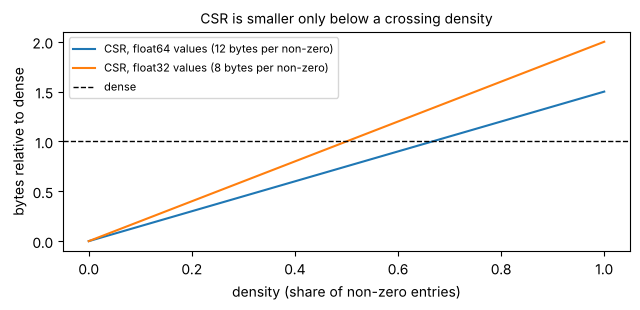

In [8]:
def csr_bytes(A):
    return A.data.nbytes + A.indices.nbytes + A.indptr.nbytes

dense_bytes = m * n * 8
print(f"{m:,d} x {n:,d} float64 matrix, dense: {dense_bytes:,d} bytes; index type {A_sp.indices.dtype}")
print("density | nnz        | CSR bytes (SciPy) | formula 12 nnz + 4 (rows + 1) | CSR / dense")
for dens in [0.001, 0.01, 0.1, 0.5, 0.6, 0.7, 0.9]:
    k = int(round(m * n * dens))
    flat = rng.choice(m * n, size=k, replace=False)
    S_ = sp.csr_matrix((np.ones(k), (flat // n, flat % n)), shape=(m, n))
    print(f"{dens:7.3f} | {k:10,d} | {csr_bytes(S_):17,d} | {12 * k + 4 * (m + 1):29,d} | {csr_bytes(S_) / dense_bytes:6.3f}")
    del S_
cross64 = (8 * m * n - 4 * (m + 1)) / 12 / (m * n)
cross32 = (4 * m * n - 4 * (m + 1)) / 8 / (m * n)
print(f"CSR and dense take the same bytes at density {cross64:.4f} (float64 values) and {cross32:.4f} (float32 values)")

V = 50_000
print(f"\nhow sparse is real data? a one-hot vector over {V:,d} words: density {1 / V:.6f}; "
      f"a document with 100 different words: {100 / V:.4f}")

dens = np.linspace(0, 1, 101)
plt.figure(figsize=(6.5, 3.2))
plt.plot(dens, 12 * dens / 8, label="CSR, float64 values (12 bytes per non-zero)")
plt.plot(dens, 8 * dens / 4, label="CSR, float32 values (8 bytes per non-zero)")
plt.axhline(1.0, color="k", ls="--", lw=1, label="dense")
plt.xlabel("density (share of non-zero entries)"); plt.ylabel("bytes relative to dense")
plt.title("CSR is smaller only below a crossing density", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 9. An embedding lookup is a one-hot product done by indexing
A language model's first layer multiplies a **one-hot** vector (all zeros, a single 1 at the token's id) by the embedding matrix $E$ of shape $V \times d$. Written as a dense product that is $V \cdot d$ multiply–adds, almost all of them with a zero. But the result is just row `token` of $E$, so frameworks **index**: copy $d$ numbers, no multiplication at all.

For a batch of token ids, the one-hot matrix is a CSR matrix with one non-zero per row, and section 7's count applies: nnz × $d$ operations instead of batch × $V$ × $d$.

In [9]:
V, d = 50_000, 64
E = rng.normal(size=(V, d)).astype(np.float32)             # a random "embedding matrix"
token = 31_337
onehot = np.zeros(V, dtype=np.float32); onehot[token] = 1.0
print("one-hot product equals the indexed row:", np.allclose(onehot @ E, E[token]))
print(f"multiply-adds, one-hot product: V * d = {V * d:,d}; lookup: 0 multiply-adds, {d} numbers copied")
t_mat, t_idx = best_of(lambda: onehot @ E, 20), best_of(lambda: E[token], 20)
print(f"time, one-hot product: {t_mat * 1e6:8.1f} microseconds")
print(f"time, lookup E[token]: {t_idx * 1e6:8.2f} microseconds")

ids = rng.integers(0, V, size=256)                         # a batch of 256 token ids
onehot_rows = sp.csr_matrix((np.ones(len(ids), dtype=np.float32), (np.arange(len(ids)), ids)), shape=(len(ids), V))
print("batch: sparse one-hot matrix times E equals E[ids]:", np.allclose(onehot_rows @ E, E[ids]))
print(f"batch of {len(ids)}: dense one-hot product {len(ids) * V * d:,d} multiply-adds; sparse product {onehot_rows.nnz * d:,d}; "
      f"lookup copies {len(ids) * d:,d} numbers")
print(f"runtime so far {time.time() - t_start:.0f} s")

one-hot product equals the indexed row: True
multiply-adds, one-hot product: V * d = 3,200,000; lookup: 0 multiply-adds, 64 numbers copied
time, one-hot product:    464.4 microseconds
time, lookup E[token]:     0.17 microseconds
batch: sparse one-hot matrix times E equals E[ids]: True
batch of 256: dense one-hot product 819,200,000 multiply-adds; sparse product 16,384; lookup copies 16,384 numbers
runtime so far 10 s


### 10. Exercises

In [10]:
# TODO: a dynamic array that multiplies its capacity by g when it is full: new capacity = max(capacity + 1, int(capacity * g)),
# starting from capacity 0. For n = 100,000 appends and g = 1.125, 1.5, 2 and 4, return a list of tuples
# (g, element copies, unused slots at the end). Use simulate() from section 6. Which g copies least? Which wastes least memory?
def growth_tradeoff(n=100_000, factors=(1.125, 1.5, 2, 4)):
    return None          # replace with your code

r = growth_tradeoff()
print("not done yet" if r is None else r)

not done yet


In [11]:
# TODO: CSC (compressed sparse column) stores the same matrix column by column: data, row indices, and a pointer per column.
# Write csr_to_csc(m, n, indptr, indices, data) with one counting sort over the columns, in O(nnz + n). Return
# (col_ptr, row_indices, csc_data). Check it on the small matrix M and against sp.csc_matrix(A_sp) for the large one.
# When is CSC the better format: for A @ x, or for picking out one column (one word of the bag-of-words matrix)?
def csr_to_csc(m, n, indptr, indices, data):
    return None          # replace with your code

r = csr_to_csc(3, 4, ip, ix, dt)
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above. The counts are exact and will be the same on your machine; the timings will not.)

1. **Counting works.** $AB$ cost 12 multiply–adds and $BA$ cost 18: the cost depends on the shapes, $m \cdot n \cdot p$. The counter inside the loop agreed with the formula for every shape, including the dense layer on a batch (32 × 784 × 128 = 3,211,264).
2. **Big-O hides the constant.** The Python loops and NumPy both did 1,728,000 multiply–adds for the 120 × 120 product, but the loops took about 1,500 times as long in this run. It is the same $O(n^3)$ with a very different constant: interpreted loops against compiled, vectorized code.
3. **Attention is quadratic in the number of tokens.** The counted cost was exactly $2n^2d + 4nd^2$. Doubling $n$ always multiplied the number of score entries by 4. The total grew by 2.67 from 64 to 128 tokens, where the four projections are still two thirds of the work, and by 3.88 from 2,048 to 4,096 tokens, where the $n^2$ part is 97.0% of it. The measured time followed the count: its log–log slope for $n \ge 512$ was close to 2 in this run, and the slope of the exact count over the same range is 1.91.
4. **Views are free, copies are not.** The transpose, the slices and the reshapes of `a` shared its 96-byte buffer and differed only in shape and strides. `a.T.reshape(12)`, the list index `a[[0, 2]]` and `.copy()` made new buffers. Writing through the view `a.T` changed `a`.
5. **The order of traversal matters, although the count is the same.** Summing the 256 MB array across its memory order took about four times as long as summing along it (4.3 times in this run); for the 16 MB and 64 MB arrays the factor was about two. In the column-major copy the columns were the fast direction. Counting additions cannot see this difference; the memory layout explains it.
6. **Geometric growth makes appends cheap on average.** 100,000 appends copied 131,071 elements with doubling (under $2n$) and 798,128 with CPython's rule (under $9n$), against 4,999,950,000 when the array grows by one. CPython's rule copies more than doubling but wastes less memory: it ended with a capacity of 100,116 against 131,072. `np.append` in a loop was tens of times slower than appending to a list and converting once, and the gap widened as $n$ grew.
7. **CSR stores only the non-zeros, and pays for that with indices.** Our three arrays equalled SciPy's. The sparse product used 100,000 multiply–adds where the dense one uses 10,000,000. In bytes, CSR won only below a density of 0.6666 with float64 values (0.4999 with float32 values); at density 0.7 it was already 5% larger than the dense array. Text data is far below that: 0.002 for a document with 100 different words out of 50,000.
8. **An embedding layer never multiplies by a one-hot vector.** The product and the lookup gave the same row. One costs 3,200,000 multiply–adds; the other copies 64 numbers.
9. These are counts on small arrays. Course 11 session 1 continues from counts to time on real hardware with the roofline model, and Course 11 session 5 times sparse against dense products for pruned networks.